# Simple logistic classifier with both the color of the pixel and the position of the pixel

Another simple classifier with the addition of new features to get where these pixels are situated

In [7]:
import h5py
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, binary_target_mask, make_data_splits, build_pixel_dataset, image_features

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, jaccard_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay


DS_STEP = 8
WITH_POSITIONS = True

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [4]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

X_train, y_train = build_pixel_dataset(nyu, train_indices, target_ids, DS_STEP,WITH_POSITIONS)
X_test, y_test = build_pixel_dataset(nyu, test_indices, target_ids, DS_STEP,WITH_POSITIONS)

Train images: 1028
Validation images: 206
Test images: 215


In [10]:
clf = LogisticRegression(class_weight="balanced", max_iter=1000)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["not floor", "floor"]))
print(f"floor IoU: {jaccard_score(y_test, y_pred):.3f}")

              precision    recall  f1-score   support

   not floor       0.98      0.76      0.86    775899
       floor       0.32      0.87      0.47    100664

    accuracy                           0.78    876563
   macro avg       0.65      0.82      0.67    876563
weighted avg       0.90      0.78      0.81    876563

floor IoU: 0.310


AUC:      0.891
Accuracy: 0.777  (baseline 'always not floor': 0.885)
[[593065 182834]
 [ 12679  87985]]


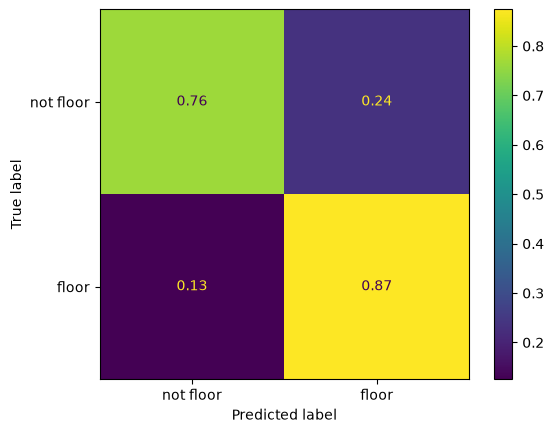

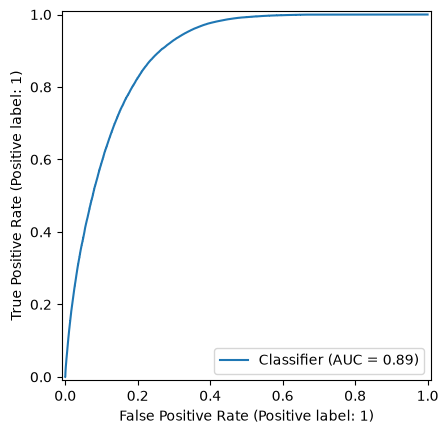

In [11]:
y_proba = clf.predict_proba(X_test)[:, 1]

print(f"AUC:      {roc_auc_score(y_test, y_proba):.3f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}  (baseline 'always not floor': {1 - y_test.mean():.3f})")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", display_labels=["not floor", "floor"])
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.show()

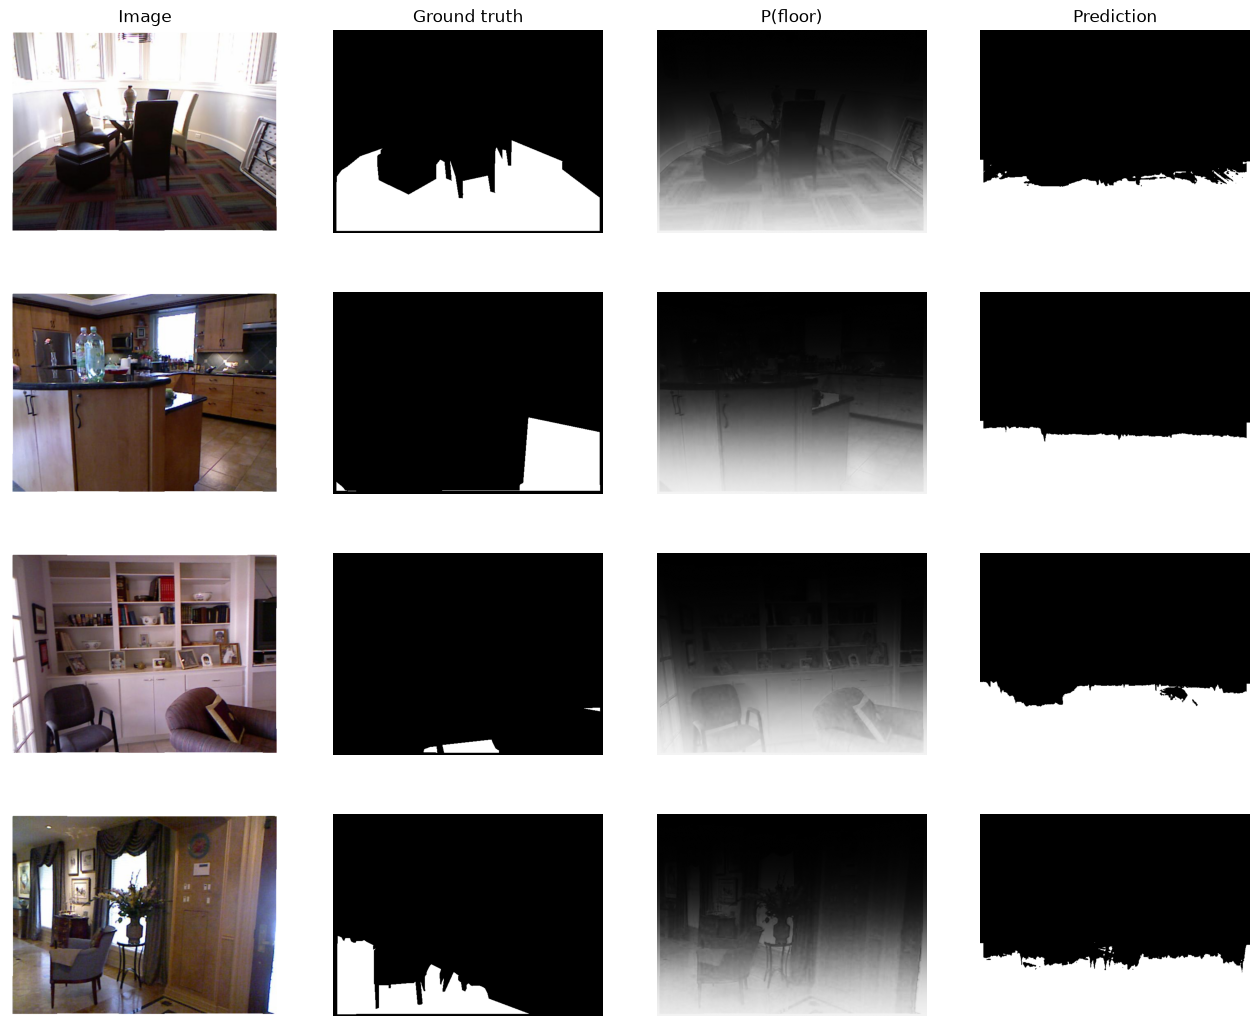

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)

    # Ground truth: 1 = floor, 0 = everything else
    gt = binary_target_mask(labels, target_ids)

    # Predict P(floor) for every pixel, then reshape back to image size
    X = image_features(image, with_position=True)
    proba = clf.predict_proba(X)[:, 1].reshape(labels.shape)

    # Final prediction
    pred = clf.predict(X).reshape(labels.shape)

    axes[row, 0].imshow(image)
    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 2].imshow(proba, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].imshow(pred, cmap="gray")

axes[0, 0].set_title("Image")
axes[0, 1].set_title("Ground truth")
axes[0, 2].set_title("P(floor)")
axes[0, 3].set_title("Prediction")

for ax in axes.ravel():
    ax.axis("off")

plt.show()